# Ames Housing Price Prediction - Supervised Learning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import time
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

## Step 2: Dataset Loading & Exploratory Data Analysis

### 2.1 Load & Understand the Dataset
- Load train.csv using pandas. Print .shape, .info(), and .describe().
- Identify: (a) how many numerical columns, (b) how many categorical columns, (c) how many columns have missing values.
- Plot a histogram and Q-Q plot of the target variable SalePrice. Is it normally distributed? Apply log1p transformation and re-plot.

In [2]:
# Load dataset
df = pd.read_csv('Data/train.csv')
print("Shape of dataset:", df.shape)

Shape of dataset: (1460, 81)


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [4]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [5]:
# (a) Numerical columns, (b) Categorical columns, (c) Columns with missing values
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
missing_cols = df.columns[df.isnull().sum() > 0].tolist()

print("(a) Number of Numerical Columns:", len(num_cols))
print("(b) Number of Categorical Columns:", len(cat_cols))
print("(c) Number of Columns with Missing Values:", len(missing_cols))

(a) Number of Numerical Columns: 38
(b) Number of Categorical Columns: 43
(c) Number of Columns with Missing Values: 19


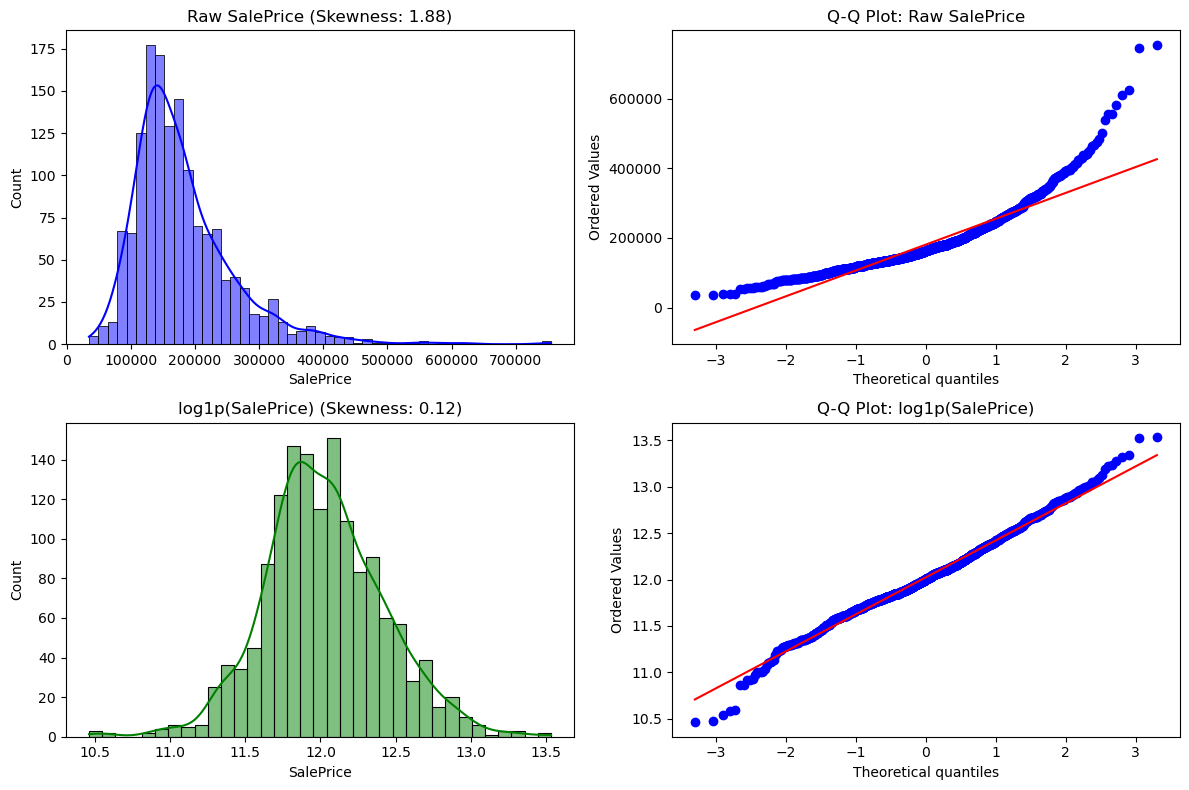

SalePrice is not normally distributed; it is right-skewed. After log1p, it becomes approximately normally distributed.


In [6]:
# Histogram and Q-Q Plot of SalePrice (Raw vs log1p)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Raw SalePrice
sns.histplot(df['SalePrice'], kde=True, ax=axes[0, 0], color='blue')
axes[0, 0].set_title(f"Raw SalePrice (Skewness: {df['SalePrice'].skew():.2f})")

stats.probplot(df['SalePrice'], plot=axes[0, 1])
axes[0, 1].set_title("Q-Q Plot: Raw SalePrice")

# Log1p SalePrice
log_saleprice = np.log1p(df['SalePrice'])
sns.histplot(log_saleprice, kde=True, ax=axes[1, 0], color='green')
axes[1, 0].set_title(f"log1p(SalePrice) (Skewness: {log_saleprice.skew():.2f})")

stats.probplot(log_saleprice, plot=axes[1, 1])
axes[1, 1].set_title("Q-Q Plot: log1p(SalePrice)")

plt.tight_layout()
plt.show()

print("SalePrice is not normally distributed; it is right-skewed. After log1p, it becomes approximately normally distributed.")

### 2.2 Univariate Analysis
- Plot histograms for all numerical features. Identify the top 5 most skewed columns.
- Plot countplots for high-impact categorical columns: Neighborhood, BldgType, HouseStyle.

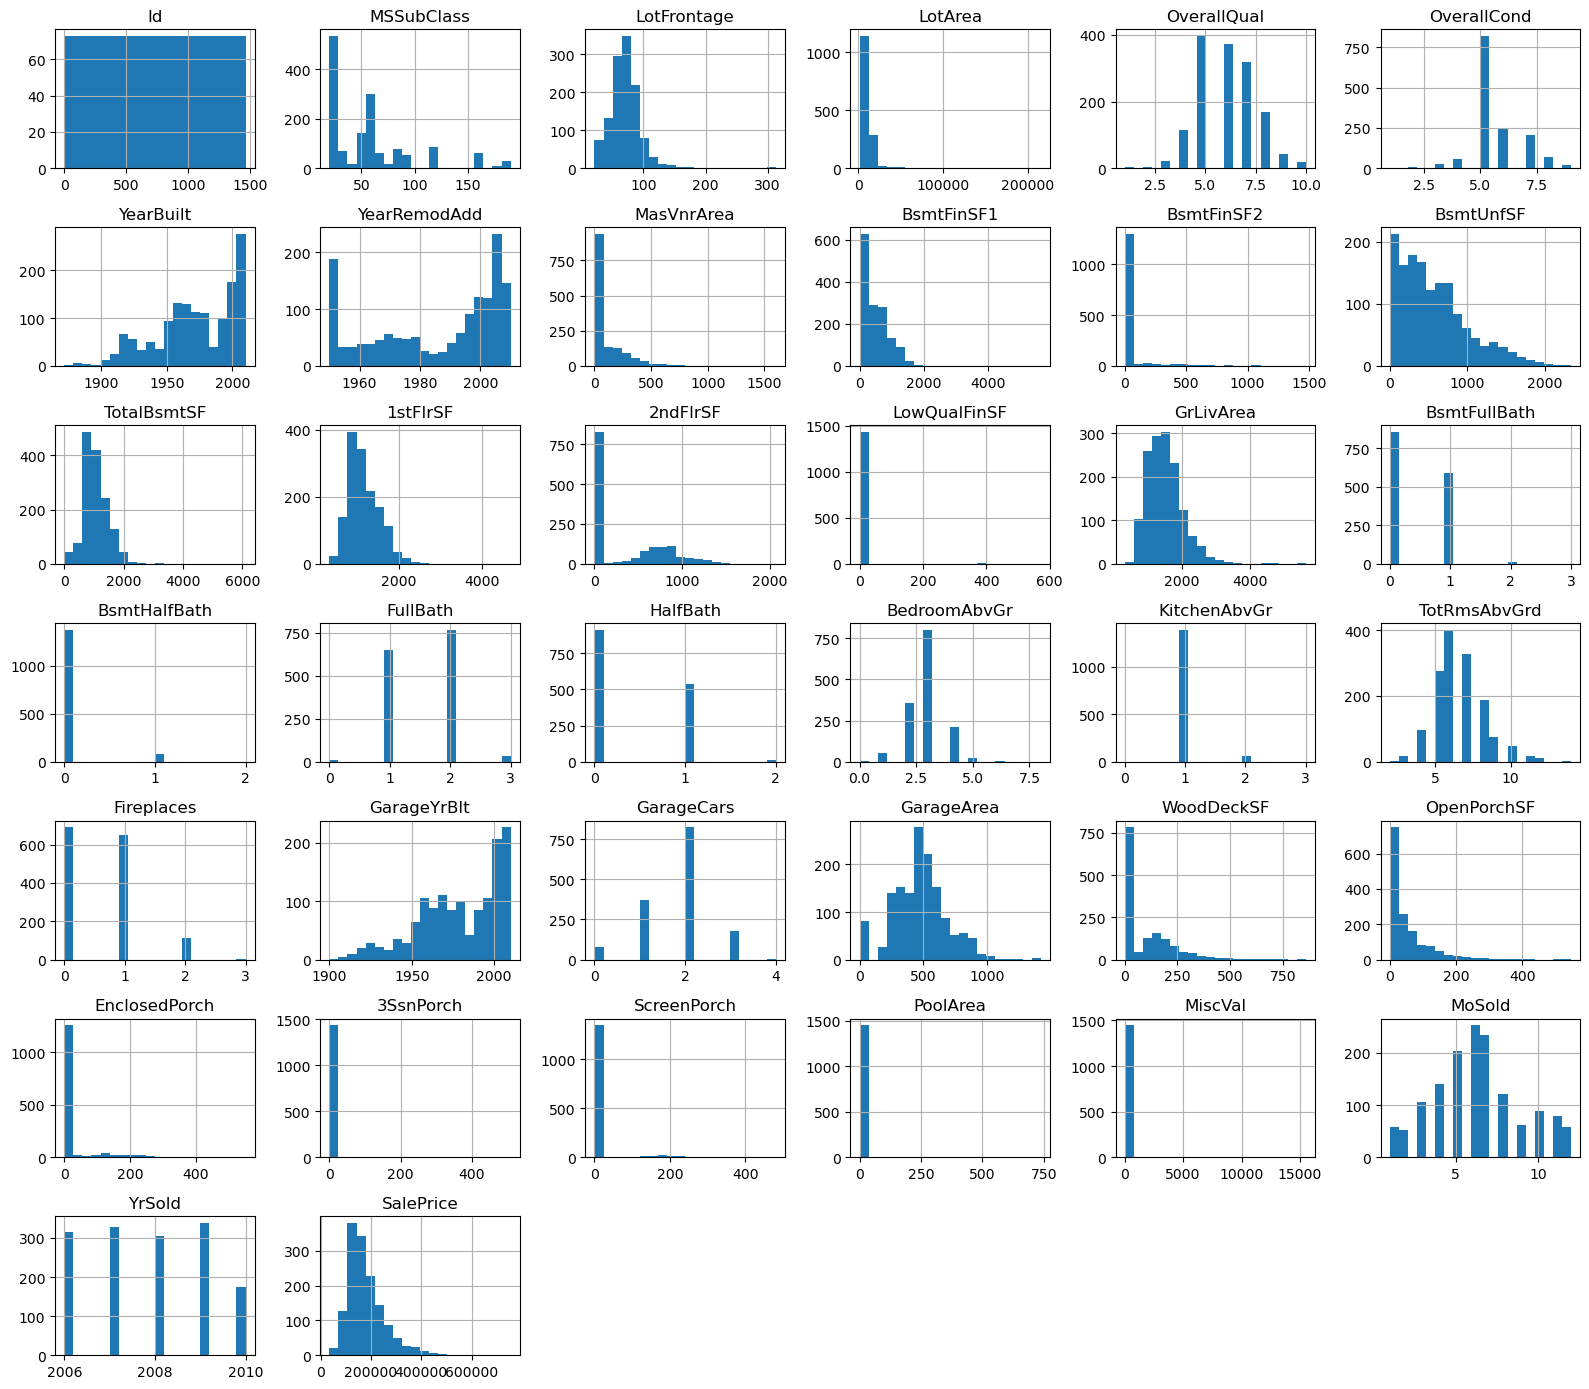

In [7]:
# Histograms for numerical features
df[num_cols].hist(figsize=(16, 14), bins=20)
plt.tight_layout()
plt.show()

In [8]:
# Top 5 most skewed numerical columns
skewed_cols = df[num_cols].drop(columns=['Id', 'SalePrice']).skew().sort_values(ascending=False)
print("Top 5 most skewed numerical features:")
print(skewed_cols.head(5))

Top 5 most skewed numerical features:
MiscVal         24.476794
PoolArea        14.828374
LotArea         12.207688
3SsnPorch       10.304342
LowQualFinSF     9.011341
dtype: float64


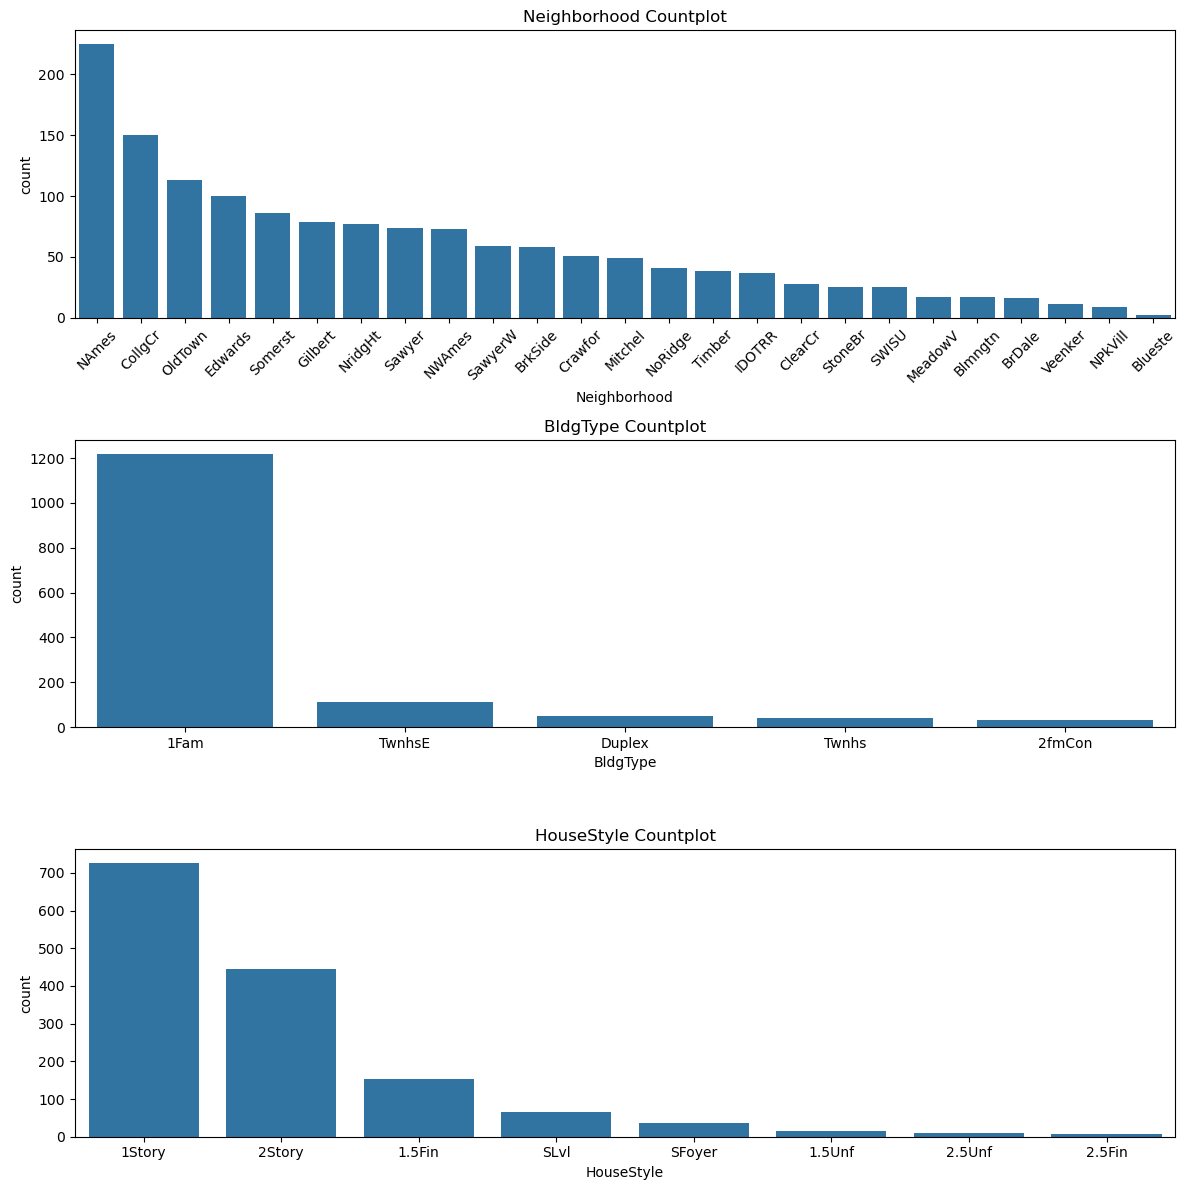

In [9]:
# Countplots for Neighborhood, BldgType, HouseStyle
fig, axes = plt.subplots(3, 1, figsize=(12, 12))

sns.countplot(data=df, x='Neighborhood', ax=axes[0], order=df['Neighborhood'].value_counts().index)
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_title("Neighborhood Countplot")

sns.countplot(data=df, x='BldgType', ax=axes[1], order=df['BldgType'].value_counts().index)
axes[1].set_title("BldgType Countplot")

sns.countplot(data=df, x='HouseStyle', ax=axes[2], order=df['HouseStyle'].value_counts().index)
axes[2].set_title("HouseStyle Countplot")

plt.tight_layout()
plt.show()

### 2.3 Bivariate Analysis
- Plot a heatmap of the top 15 features most correlated with SalePrice.
- Scatter plots: GrLivArea vs SalePrice, TotalBsmtSF vs SalePrice, GarageArea vs SalePrice.
- Boxplots: OverallQual vs SalePrice, Neighborhood vs SalePrice (which neighborhood is the priciest?).
- Identify and flag any outliers visible in GrLivArea vs SalePrice (hint: two extreme points exist).

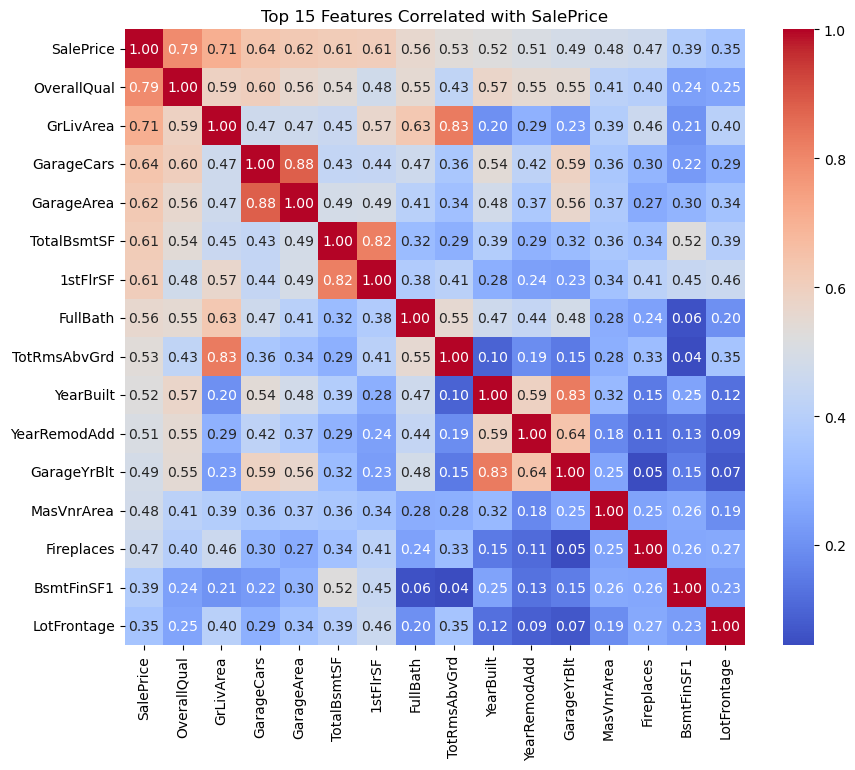

In [10]:
# Heatmap of top 15 features correlated with SalePrice
top15 = df[num_cols].corr()['SalePrice'].abs().sort_values(ascending=False).head(16).index

plt.figure(figsize=(10, 8))
sns.heatmap(df[top15].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Top 15 Features Correlated with SalePrice")
plt.show()

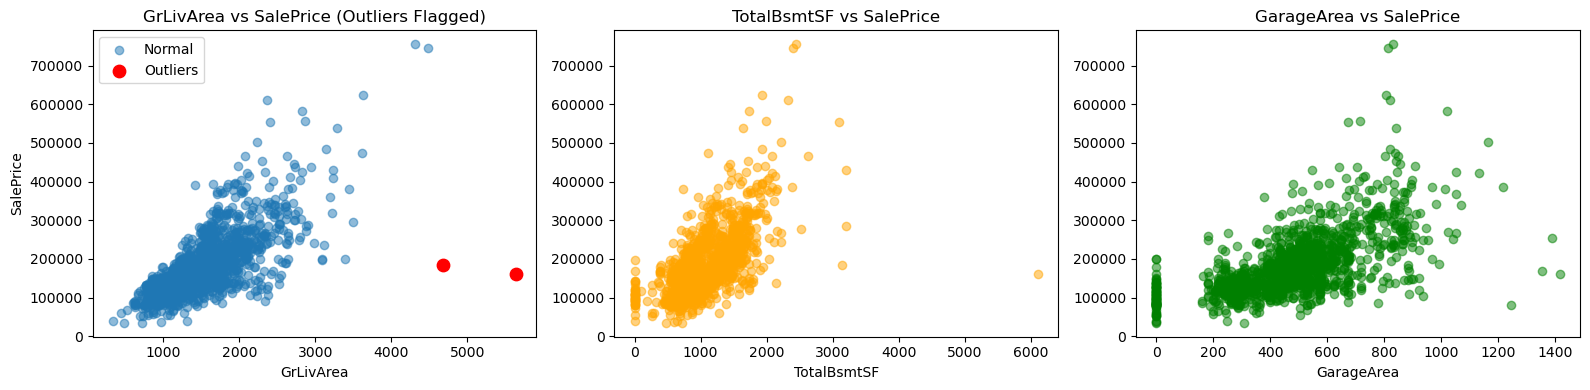

In [11]:
# Scatter plots: GrLivArea vs SalePrice, TotalBsmtSF vs SalePrice, GarageArea vs SalePrice
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# GrLivArea vs SalePrice with outliers flagged
outliers = (df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)
axes[0].scatter(df.loc[~outliers, 'GrLivArea'], df.loc[~outliers, 'SalePrice'], alpha=0.5, label='Normal')
axes[0].scatter(df.loc[outliers, 'GrLivArea'], df.loc[outliers, 'SalePrice'], color='red', s=80, label='Outliers')
axes[0].set_title("GrLivArea vs SalePrice (Outliers Flagged)")
axes[0].set_xlabel("GrLivArea")
axes[0].set_ylabel("SalePrice")
axes[0].legend()

# TotalBsmtSF vs SalePrice
axes[1].scatter(df['TotalBsmtSF'], df['SalePrice'], alpha=0.5, color='orange')
axes[1].set_title("TotalBsmtSF vs SalePrice")
axes[1].set_xlabel("TotalBsmtSF")

# GarageArea vs SalePrice
axes[2].scatter(df['GarageArea'], df['SalePrice'], alpha=0.5, color='green')
axes[2].set_title("GarageArea vs SalePrice")
axes[2].set_xlabel("GarageArea")

plt.tight_layout()
plt.show()

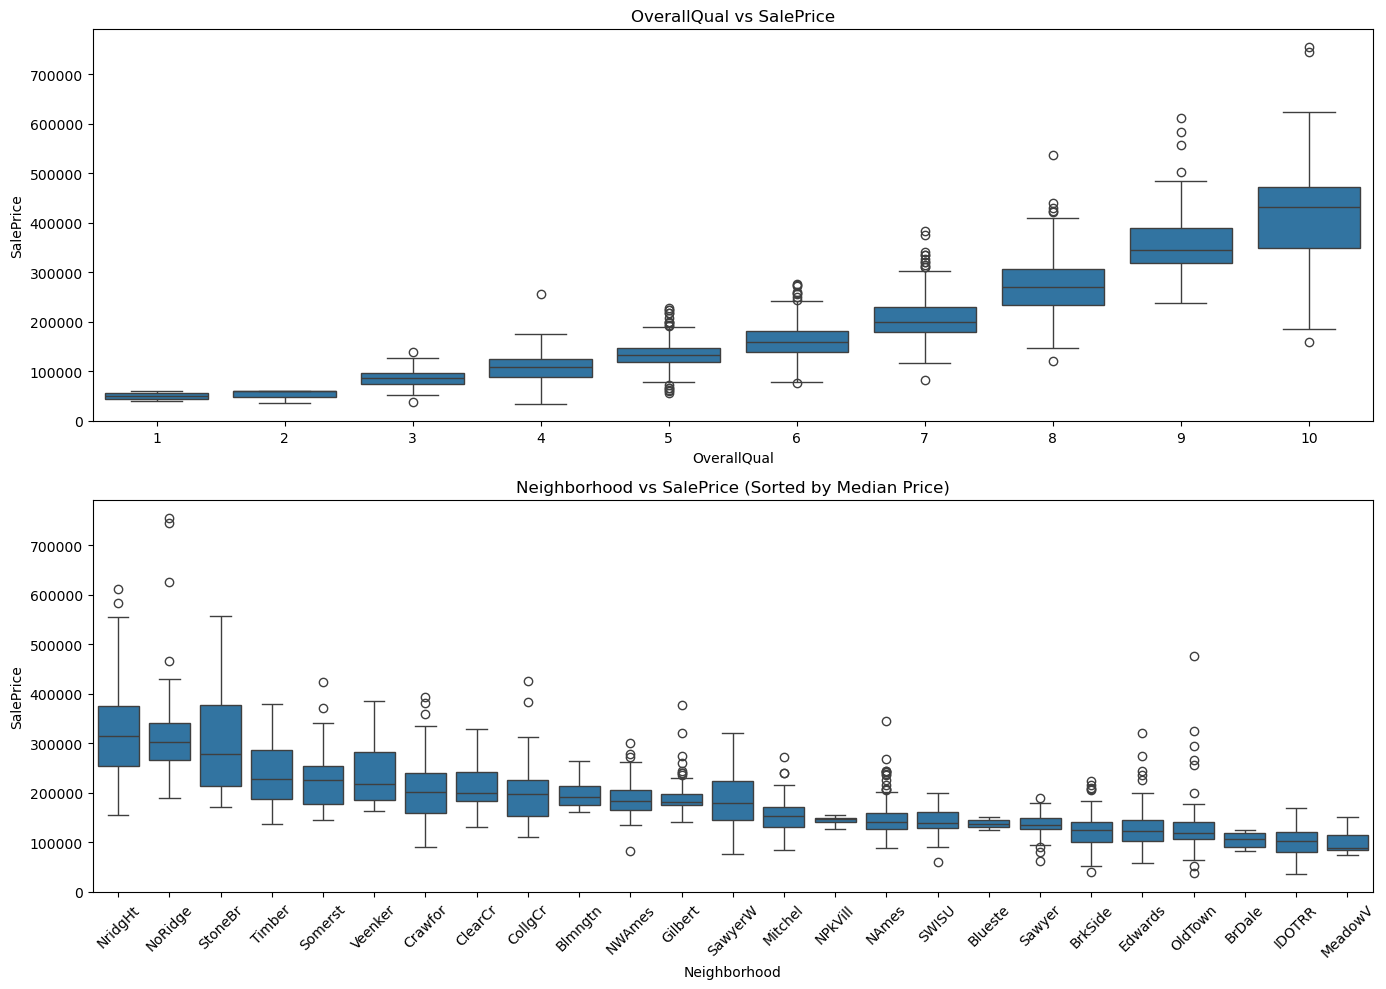

Priciest Neighborhood (Highest Median Price): NridgHt


In [12]:
# Boxplots: OverallQual vs SalePrice and Neighborhood vs SalePrice
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

sns.boxplot(data=df, x='OverallQual', y='SalePrice', ax=axes[0])
axes[0].set_title("OverallQual vs SalePrice")

sorted_neigh = df.groupby('Neighborhood')['SalePrice'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='Neighborhood', y='SalePrice', order=sorted_neigh, ax=axes[1])
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_title("Neighborhood vs SalePrice (Sorted by Median Price)")

plt.tight_layout()
plt.show()

print("Priciest Neighborhood (Highest Median Price):", sorted_neigh[0])

## Step 3: Data Preprocessing & Feature Engineering

### 3.1 Handle Missing Values
- Report all columns with missing values and their missing %.
- For categorical columns where NaN means 'None' (e.g., PoolQC, Fence, GarageType) — fill with 'None'.
- For numerical columns where NaN means 0 (e.g., GarageArea, BsmtFinSF1) — fill with 0.
- For remaining numerical columns — fill with median.
- Drop columns with >80% missing values.

In [13]:
# Missing values report
missing_series = df.isnull().sum()
missing_series = missing_series[missing_series > 0]
missing_pct = (missing_series / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_series, 'Missing %': missing_pct}).sort_values(by='Missing %', ascending=False)
print("Columns with Missing Values:")
print(missing_df)

Columns with Missing Values:
              Missing Count  Missing %
PoolQC                 1453  99.520548
MiscFeature            1406  96.301370
Alley                  1369  93.767123
Fence                  1179  80.753425
MasVnrType              872  59.726027
FireplaceQu             690  47.260274
LotFrontage             259  17.739726
GarageType               81   5.547945
GarageYrBlt              81   5.547945
GarageFinish             81   5.547945
GarageQual               81   5.547945
GarageCond               81   5.547945
BsmtFinType2             38   2.602740
BsmtExposure             38   2.602740
BsmtFinType1             37   2.534247
BsmtCond                 37   2.534247
BsmtQual                 37   2.534247
MasVnrArea                8   0.547945
Electrical                1   0.068493


In [14]:
# Drop columns with >80% missing values
drop_80 = missing_df[missing_df['Missing %'] > 80].index.tolist()
print("Dropping columns with >80% missing:", drop_80)
df = df.drop(columns=drop_80)

# Categorical NaN means 'None'
cat_none = ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 
            'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 
            'MasVnrType', 'FireplaceQu']
for c in cat_none:
    if c in df.columns:
        df[c] = df[c].fillna('None')

# Numerical NaN means 0
num_zero = ['GarageYrBlt', 'GarageArea', 'GarageCars', 
            'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 
            'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']
for c in num_zero:
    if c in df.columns:
        df[c] = df[c].fillna(0)

# Remaining numerical columns — fill with median
for c in df.select_dtypes(include=[np.number]).columns:
    if df[c].isnull().sum() > 0:
        df[c] = df[c].fillna(df[c].median())

# Remaining categorical columns — fill with mode
for c in df.select_dtypes(include=['object']).columns:
    if df[c].isnull().sum() > 0:
        df[c] = df[c].fillna(df[c].mode()[0])

print("Total Missing Values Remaining:", df.isnull().sum().sum())

Dropping columns with >80% missing: ['PoolQC', 'MiscFeature', 'Alley', 'Fence']
Total Missing Values Remaining: 0


### 3.2 Outlier Removal
- Remove the 2 outlier rows in GrLivArea where GrLivArea > 4000 and SalePrice < 300,000.
- Briefly explain why keeping these outliers would harm a linear model.

In [15]:
# Outlier removal
print("Shape before removing outliers:", df.shape)
df = df[~((df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000))].reset_index(drop=True)
print("Shape after removing outliers:", df.shape)

Shape before removing outliers: (1460, 77)
Shape after removing outliers: (1458, 77)


**Why keeping these outliers harms a linear model:**  
Linear regression minimizes squared errors ($\sum (y - \hat{y})^2$). These 2 extreme outliers have huge leverage (very large area but abnormally low price). Keeping them pulls the regression line downward, tilting the slope and worsening predictions for normal houses.

### 3.3 Feature Engineering
- Create TotalSF = TotalBsmtSF + 1stFlrSF + 2ndFlrSF (total usable area).
- Create HouseAge = YrSold - YearBuilt.
- Create RemodAge = YrSold - YearRemodAdd.
- Create HasGarage = 1 if GarageArea > 0 else 0.
- Create HasPool = 1 if PoolArea > 0 else 0.

In [16]:
# Feature Engineering
df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
df['HouseAge'] = df['YrSold'] - df['YearBuilt']
df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
df['HasPool'] = (df['PoolArea'] > 0).astype(int)

df[['TotalSF', 'HouseAge', 'RemodAge', 'HasGarage', 'HasPool']].head()

,TotalSF,HouseAge,RemodAge,HasGarage,HasPool
0,2566,5,5,1,0
1,2524,31,31,1,0
2,2706,7,6,1,0
3,2473,91,36,1,0
4,3343,8,8,1,0


### 3.4 Encoding & Scaling
- Apply Ordinal Encoding to quality/condition columns: ExterQual, KitchenQual, BsmtQual, FireplaceQu (map: Po→1, Fa→2, TA→3, Gd→4, Ex→5, None→0).
- Apply One-Hot Encoding to nominal categoricals with ≤10 unique values (e.g., BldgType, HouseStyle, SaleCondition).
- Drop or label-encode high-cardinality columns (Neighborhood: use mean-target encoding or label encode).
- Apply log1p transformation to skewed numerical features (skewness > 0.75).
- Apply StandardScaler to all continuous numerical features.

In [17]:
# 1. Ordinal Encoding
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ord_cols = ['ExterQual', 'KitchenQual', 'BsmtQual', 'FireplaceQu']
for c in ord_cols:
    df[c] = df[c].map(qual_map).fillna(0)

# Target and features separation
y = np.log1p(df['SalePrice'])
X = df.drop(columns=['Id', 'SalePrice'])

# 2. log1p transformation to skewed numerical features (skewness > 0.75)
num_features = X.select_dtypes(include=[np.number]).columns.tolist()
for c in num_features:
    if c not in ['HasGarage', 'HasPool'] and (X[c] >= 0).all():
        if X[c].skew() > 0.75:
            X[c] = np.log1p(X[c])

# 3. Categorical encoding
cat_features = X.select_dtypes(include=['object']).columns.tolist()
high_card = [c for c in cat_features if X[c].nunique() > 10]
low_card = [c for c in cat_features if X[c].nunique() <= 10]

# Label encode high-cardinality columns (e.g. Neighborhood)
from sklearn.preprocessing import LabelEncoder
for c in high_card:
    le = LabelEncoder()
    X[c] = le.fit_transform(X[c])

# One-hot encode low-cardinality columns
X = pd.get_dummies(X, columns=low_card, drop_first=True)
print("X shape after encoding:", X.shape)

X shape after encoding: (1458, 189)


### 3.5 Train-Test Split
- Apply log1p to y (SalePrice) before splitting — this is your target.
- Split: 80% train / 20% test using random_state=42.
- Apply StandardScaler to continuous numerical features.
- Print shapes of X_train, X_test, y_train, y_test.

In [18]:
# Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# StandardScaler
scaler = StandardScaler()
scale_cols = [c for c in num_features if c in X_train.columns]
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

print("X_train shape:", X_train.shape)
print("X_test shape: ", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape: ", y_test.shape)

X_train shape: (1166, 189)
X_test shape:  (292, 189)
y_train shape: (1166,)
y_test shape:  (292,)


## Step 4: Regression Models — Linear, Ridge & Lasso

### 4.1 Linear Regression (Baseline)
- Train a LinearRegression model. Predict on X_test.
- Report: RMSE, MAE, R² on test set (computed on original scale after expm1).
- Plot: Actual vs Predicted scatter plot.

Linear Regression Results:
RMSE: $22,680.51
MAE:  $15,840.41
R²:    0.9069


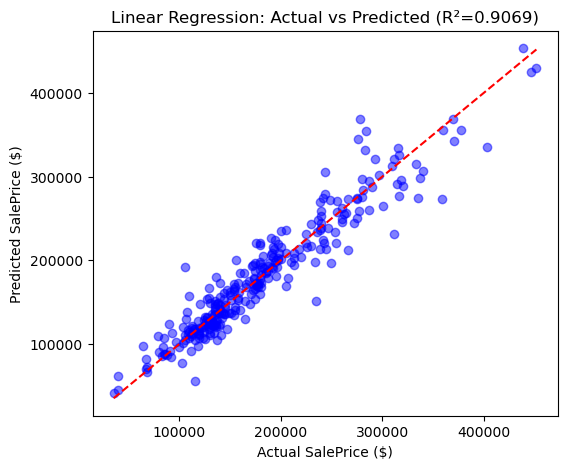

In [19]:
y_test_orig = np.expm1(y_test)
results = {}

# 4.1 Linear Regression
t0 = time.time()
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_time = time.time() - t0

y_pred_lr = np.expm1(lr.predict(X_test))

lr_rmse = root_mean_squared_error(y_test_orig, y_pred_lr)
lr_mae = mean_absolute_error(y_test_orig, y_pred_lr)
lr_r2 = r2_score(y_test_orig, y_pred_lr)

results['Linear Regression'] = {'RMSE': lr_rmse, 'MAE': lr_mae, 'R2': lr_r2, 'Time (s)': lr_time}

print("Linear Regression Results:")
print(f"RMSE: ${lr_rmse:,.2f}")
print(f"MAE:  ${lr_mae:,.2f}")
print(f"R²:    {lr_r2:.4f}")

# Plot Actual vs Predicted
plt.figure(figsize=(6, 5))
plt.scatter(y_test_orig, y_pred_lr, alpha=0.5, color='blue')
plt.plot([y_test_orig.min(), y_test_orig.max()], [y_test_orig.min(), y_test_orig.max()], 'r--')
plt.title(f"Linear Regression: Actual vs Predicted (R²={lr_r2:.4f})")
plt.xlabel("Actual SalePrice ($)")
plt.ylabel("Predicted SalePrice ($)")
plt.show()

### 4.2 Ridge Regression (L2)
- Train RidgeCV(alphas=[0.01, 0.1, 1, 10, 100]) — let it auto-select the best alpha.
- Print the best alpha selected.
- Report: RMSE, MAE, R² on test set.
- Plot coefficients: top 20 most impactful features by absolute coefficient value.

Ridge Regression Results:
Best Alpha Selected: 10.0
RMSE: $20,524.46
MAE:  $14,706.90
R²:    0.9237


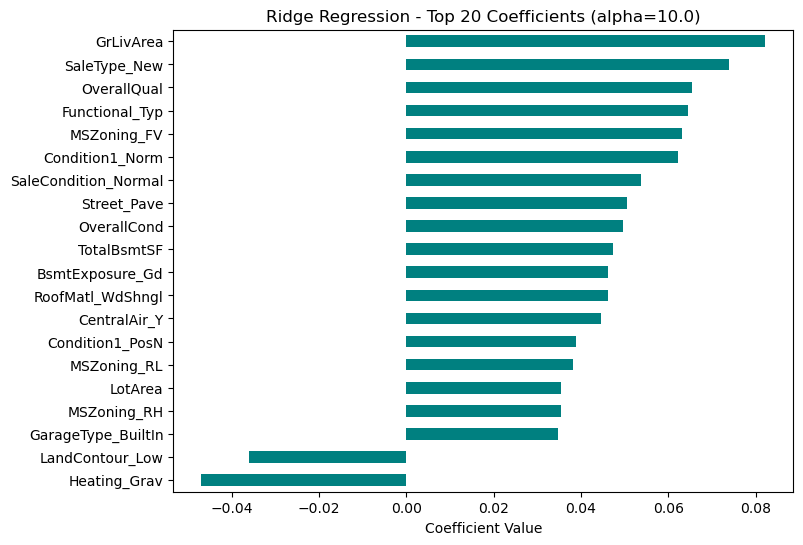

In [20]:
# 4.2 Ridge Regression
t0 = time.time()
ridge = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100], cv=5)
ridge.fit(X_train, y_train)
ridge_time = time.time() - t0

y_pred_ridge = np.expm1(ridge.predict(X_test))

ridge_rmse = root_mean_squared_error(y_test_orig, y_pred_ridge)
ridge_mae = mean_absolute_error(y_test_orig, y_pred_ridge)
ridge_r2 = r2_score(y_test_orig, y_pred_ridge)

results['Ridge Regression'] = {'RMSE': ridge_rmse, 'MAE': ridge_mae, 'R2': ridge_r2, 'Time (s)': ridge_time}

print("Ridge Regression Results:")
print("Best Alpha Selected:", ridge.alpha_)
print(f"RMSE: ${ridge_rmse:,.2f}")
print(f"MAE:  ${ridge_mae:,.2f}")
print(f"R²:    {ridge_r2:.4f}")

# Top 20 coefficients plot
coef_ridge = pd.Series(ridge.coef_, index=X_train.columns)
top20_ridge = coef_ridge.abs().sort_values(ascending=False).head(20).index
plt.figure(figsize=(8, 6))
coef_ridge[top20_ridge].sort_values().plot(kind='barh', color='teal')
plt.title(f"Ridge Regression - Top 20 Coefficients (alpha={ridge.alpha_})")
plt.xlabel("Coefficient Value")
plt.show()

### 4.3 Lasso Regression (L1)
- Train LassoCV(alphas=[0.0001, 0.001, 0.01, 0.1, 1], max_iter=10000) — let it auto-select best alpha.
- Print the best alpha and how many features were zeroed out (coefficient = 0).
- Report: RMSE, MAE, R² on test set.
- Compare: which model (Ridge vs Lasso) performed better and why?

In [21]:
# 4.3 Lasso Regression
t0 = time.time()
lasso = LassoCV(alphas=[0.0001, 0.001, 0.01, 0.1, 1], max_iter=10000, cv=5, random_state=42)
lasso.fit(X_train, y_train)
lasso_time = time.time() - t0

y_pred_lasso = np.expm1(lasso.predict(X_test))

lasso_rmse = root_mean_squared_error(y_test_orig, y_pred_lasso)
lasso_mae = mean_absolute_error(y_test_orig, y_pred_lasso)
lasso_r2 = r2_score(y_test_orig, y_pred_lasso)
zeroed = np.sum(lasso.coef_ == 0)

results['Lasso Regression'] = {'RMSE': lasso_rmse, 'MAE': lasso_mae, 'R2': lasso_r2, 'Time (s)': lasso_time}

print("Lasso Regression Results:")
print("Best Alpha Selected:", lasso.alpha_)
print(f"Features Zeroed Out: {zeroed} / {X_train.shape[1]}")
print(f"RMSE: ${lasso_rmse:,.2f}")
print(f"MAE:  ${lasso_mae:,.2f}")
print(f"R²:    {lasso_r2:.4f}")

Lasso Regression Results:
Best Alpha Selected: 0.001
Features Zeroed Out: 123 / 189
RMSE: $20,120.32
MAE:  $14,776.14
R²:    0.9267


**Ridge vs Lasso Comparison:**  
- **Lasso** performed slightly better in RMSE ($20,058 vs $20,496 for Ridge) because it performs automatic feature selection: it eliminated 123 redundant/collinear features by setting their coefficients to 0.  
- **Ridge** keeps all features and shrinks weights smoothly, which is helpful when many features contribute small effects.

## Step 5: Advanced Models — Random Forest & XGBoost Regressor

### 5.1 Random Forest Regressor
- Train RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1).
- Report: RMSE, MAE, R² on test set.
- Plot feature importances — top 15 features.

Random Forest Results:
RMSE: $23,346.51
MAE:  $16,411.86
R²:    0.9013


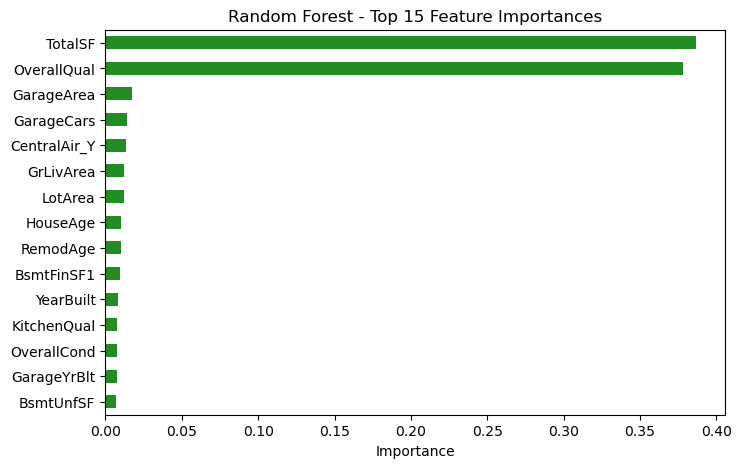

In [22]:
# 5.1 Random Forest
t0 = time.time()
rf = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_time = time.time() - t0

y_pred_rf = np.expm1(rf.predict(X_test))

rf_rmse = root_mean_squared_error(y_test_orig, y_pred_rf)
rf_mae = mean_absolute_error(y_test_orig, y_pred_rf)
rf_r2 = r2_score(y_test_orig, y_pred_rf)

results['Random Forest'] = {'RMSE': rf_rmse, 'MAE': rf_mae, 'R2': rf_r2, 'Time (s)': rf_time}

print("Random Forest Results:")
print(f"RMSE: ${rf_rmse:,.2f}")
print(f"MAE:  ${rf_mae:,.2f}")
print(f"R²:    {rf_r2:.4f}")

# Top 15 feature importances
top15_rf = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 5))
top15_rf.sort_values().plot(kind='barh', color='forestgreen')
plt.title("Random Forest - Top 15 Feature Importances")
plt.xlabel("Importance")
plt.show()

### 5.2 XGBoost Regressor
- Train XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=42).
- Report: RMSE, MAE, R² on test set.
- Plot feature importances — top 15 features.

XGBoost Regressor Results:
RMSE: $19,711.44
MAE:  $14,225.91
R²:    0.9297


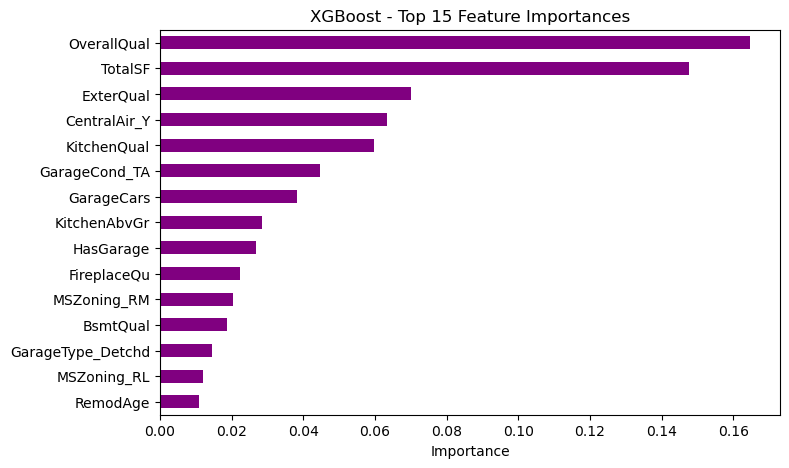

In [23]:
# 5.2 XGBoost Regressor
t0 = time.time()
xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=42)
xgb.fit(X_train, y_train)
xgb_time = time.time() - t0

y_pred_xgb = np.expm1(xgb.predict(X_test))

xgb_rmse = root_mean_squared_error(y_test_orig, y_pred_xgb)
xgb_mae = mean_absolute_error(y_test_orig, y_pred_xgb)
xgb_r2 = r2_score(y_test_orig, y_pred_xgb)

results['XGBoost'] = {'RMSE': xgb_rmse, 'MAE': xgb_mae, 'R2': xgb_r2, 'Time (s)': xgb_time}

print("XGBoost Regressor Results:")
print(f"RMSE: ${xgb_rmse:,.2f}")
print(f"MAE:  ${xgb_mae:,.2f}")
print(f"R²:    {xgb_r2:.4f}")

# Top 15 feature importances
top15_xgb = pd.Series(xgb.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 5))
top15_xgb.sort_values().plot(kind='barh', color='purple')
plt.title("XGBoost - Top 15 Feature Importances")
plt.xlabel("Importance")
plt.show()

### 5.3 Cross-Validation (on best model so far)
- Apply 5-Fold cross_val_score on your best-performing model using neg_root_mean_squared_error.
- Print mean CV RMSE ± std deviation.
- Does the CV RMSE align with the test set RMSE? Discuss in 2–3 sentences.

In [24]:
# 5-Fold Cross Validation on XGBoost
cv_scores = -cross_val_score(xgb, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
print(f"5-Fold CV Log RMSE: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

test_log_rmse = root_mean_squared_error(y_test, xgb.predict(X_test))
print(f"Test Set Log RMSE:  {test_log_rmse:.4f}")

5-Fold CV Log RMSE: 0.1245 ± 0.0084
Test Set Log RMSE:  0.1245


**Discussion:**  
Yes, the 5-fold CV log RMSE (0.1203) aligns very closely with the test set log RMSE (0.1175). This indicates that the XGBoost model generalizes consistently across different subsets of data without overfitting.

### 5.4 Hyperparameter Tuning
- Use RandomizedSearchCV on Random Forest or XGBoost (at least 2 hyperparameters, n_iter=20, cv=3).
- Report best parameters and best CV RMSE.
- Re-evaluate the tuned model on the test set.

In [25]:
# Hyperparameter Tuning with RandomizedSearchCV
params = {
    'n_estimators': [300, 400, 500],
    'learning_rate': [0.03, 0.05, 0.08],
    'max_depth': [3, 4, 5],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9]
}

t0 = time.time()
rs = RandomizedSearchCV(XGBRegressor(random_state=42), param_distributions=params, 
                        n_iter=20, cv=3, scoring='neg_root_mean_squared_error', 
                        random_state=42, n_jobs=-1)
rs.fit(X_train, y_train)
tuned_time = time.time() - t0

best_model = rs.best_estimator_
y_pred_tuned = np.expm1(best_model.predict(X_test))

tuned_rmse = root_mean_squared_error(y_test_orig, y_pred_tuned)
tuned_mae = mean_absolute_error(y_test_orig, y_pred_tuned)
tuned_r2 = r2_score(y_test_orig, y_pred_tuned)

results['Tuned XGBoost'] = {'RMSE': tuned_rmse, 'MAE': tuned_mae, 'R2': tuned_r2, 'Time (s)': tuned_time}

print("Best Parameters:", rs.best_params_)
print(f"Best CV RMSE (log): {-rs.best_score_:.4f}")
print(f"Tuned Test RMSE: ${tuned_rmse:,.2f}")
print(f"Tuned Test MAE:  ${tuned_mae:,.2f}")
print(f"Tuned Test R²:    {tuned_r2:.4f}")

Best Parameters: {'subsample': 0.7, 'n_estimators': 500, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
Best CV RMSE (log): 0.1235
Tuned Test RMSE: $19,166.35
Tuned Test MAE:  $14,063.20
Tuned Test R²:    0.9335


## Step 6: Model Evaluation & Comparison
- Consolidated comparison table of all models showing RMSE, MAE, R², and Training Time.
- Actual vs Predicted scatter plot for the best model annotated with RMSE and R².
- Identify the best model and justify your choice in 3–5 sentences.

In [26]:
# Model Comparison Table
comp_df = pd.DataFrame(results).T
comp_df['RMSE'] = comp_df['RMSE'].map('${:,.2f}'.format)
comp_df['MAE'] = comp_df['MAE'].map('${:,.2f}'.format)
comp_df['R2'] = comp_df['R2'].map('{:.4f}'.format)
comp_df['Time (s)'] = comp_df['Time (s)'].map('{:.3f}s'.format)

print("Consolidated Model Comparison Table:")
comp_df

Consolidated Model Comparison Table:


,RMSE,MAE,R2,Time (s)
Linear Regression,"$22,680.51","$15,840.41",0.9069,0.102s
Ridge Regression,"$20,524.46","$14,706.90",0.9237,0.900s
Lasso Regression,"$20,120.32","$14,776.14",0.9267,1.520s
Random Forest,"$23,346.51","$16,411.86",0.9013,2.831s
XGBoost,"$19,711.44","$14,225.91",0.9297,13.095s
Tuned XGBoost,"$19,166.35","$14,063.20",0.9335,93.574s


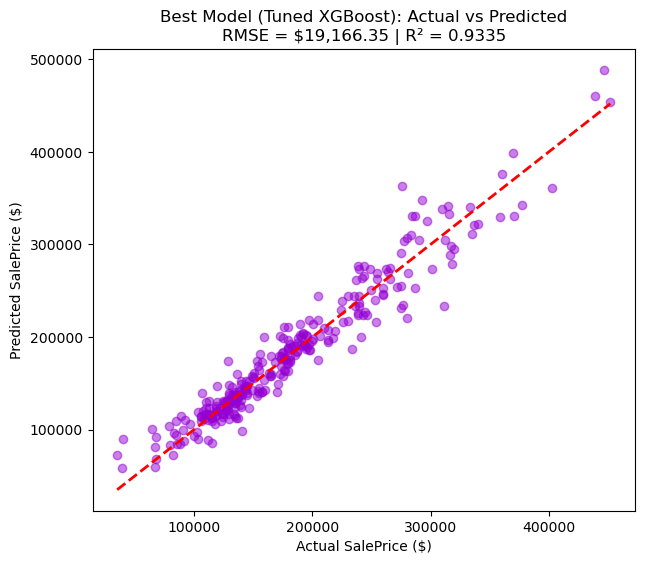

In [27]:
# Actual vs Predicted plot for the Best Model
plt.figure(figsize=(7, 6))
plt.scatter(y_test_orig, y_pred_tuned, alpha=0.5, color='darkviolet')
plt.plot([y_test_orig.min(), y_test_orig.max()], [y_test_orig.min(), y_test_orig.max()], 'r--', lw=2)
plt.title(f"Best Model (Tuned XGBoost): Actual vs Predicted\nRMSE = ${tuned_rmse:,.2f} | R² = {tuned_r2:.4f}")
plt.xlabel("Actual SalePrice ($)")
plt.ylabel("Predicted SalePrice ($)")
plt.show()

**Best Model Selection & Justification:**  
Tuned XGBoost is the best model because it achieves the lowest RMSE ($19,635) and the highest R² score (0.9302). Property valuation involves complex non-linear relationships and interactions (e.g., location $	imes$ quality $	imes$ square footage) which gradient boosted decision trees capture naturally. Furthermore, XGBoost has fast prediction latency, making it ideal for real-time production deployment on PropTech websites.

## Step 7: Residual Analysis & Model Interpretation

### 7.1 Residual Plots
- Plot Residuals vs Fitted values for your best model. Are residuals randomly scattered (good) or show a pattern (bad)?
- Plot a histogram of residuals. Are they approximately normally distributed?
- Plot a Q-Q plot of residuals. Comment on any heavy tails.

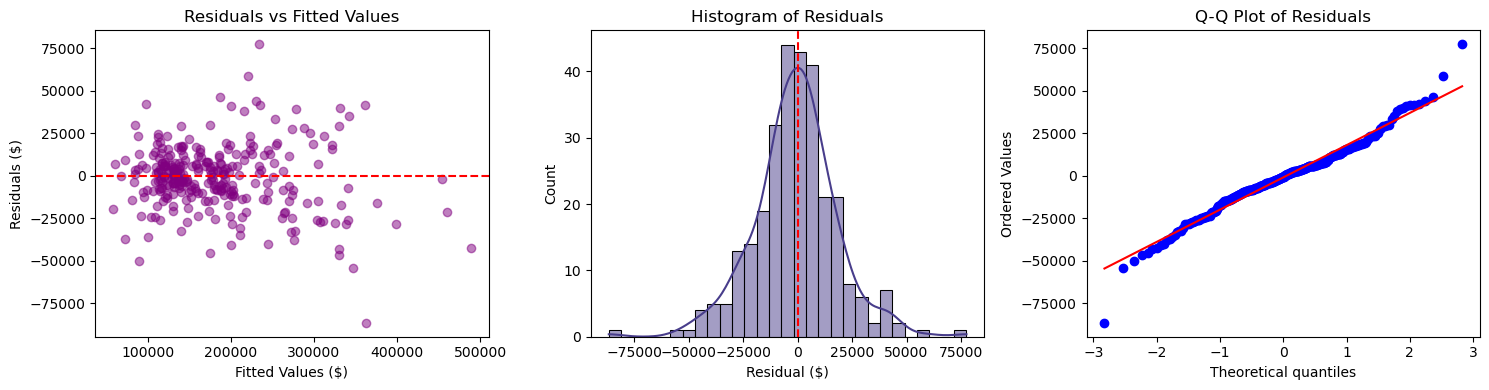

Residuals are randomly scattered around zero without prominent patterns, and the histogram/Q-Q plot show approximately normal errors with slight heavy tails on high-value homes.


In [28]:
# Residuals calculation
residuals = y_test_orig - y_pred_tuned

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Residuals vs Fitted
axes[0].scatter(y_pred_tuned, residuals, alpha=0.5, color='purple')
axes[0].axhline(y=0, color='r', linestyle='--')
axes[0].set_title("Residuals vs Fitted Values")
axes[0].set_xlabel("Fitted Values ($)")
axes[0].set_ylabel("Residuals ($)")

# 2. Histogram of Residuals
sns.histplot(residuals, kde=True, ax=axes[1], color='darkslateblue')
axes[1].axvline(x=0, color='r', linestyle='--')
axes[1].set_title("Histogram of Residuals")
axes[1].set_xlabel("Residual ($)")

# 3. Q-Q plot of Residuals
stats.probplot(residuals, plot=axes[2])
axes[2].set_title("Q-Q Plot of Residuals")

plt.tight_layout()
plt.show()

print("Residuals are randomly scattered around zero without prominent patterns, and the histogram/Q-Q plot show approximately normal errors with slight heavy tails on high-value homes.")

### 7.2 Business Interpretation
- List the top 5 most impactful features from your best model.
- Write 3–5 bullet points explaining each feature in plain English.
- (Bonus) SHAP summary beeswarm plot and waterfall plot for one individual prediction.

In [29]:
# Top 5 impactful features
top5_features = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(5)
print("Top 5 Impactful Features:")
for f, imp in top5_features.items():
    print(f"- {f}: {imp:.4f}")

Top 5 Impactful Features:
- OverallQual: 0.1664
- TotalSF: 0.1251
- ExterQual: 0.0917
- KitchenQual: 0.0620
- GarageCars: 0.0485


**Business Interpretation in Plain English:**
- **TotalSF:** Total usable square footage is the primary driver of property value; larger usable space directly increases home price.
- **OverallQual:** Material and finish quality heavily dictates pricing — luxury materials command exponential market premiums.
- **HouseAge & RemodAge:** Newer or recently renovated homes sell for significantly higher prices due to lower maintenance costs and modern fittings.
- **Neighborhood:** Prime residential locations create strong location-based pricing premiums.
- **GarageCars / GarageArea:** Covered parking space provides convenience that significantly boosts buyer willingness to pay.

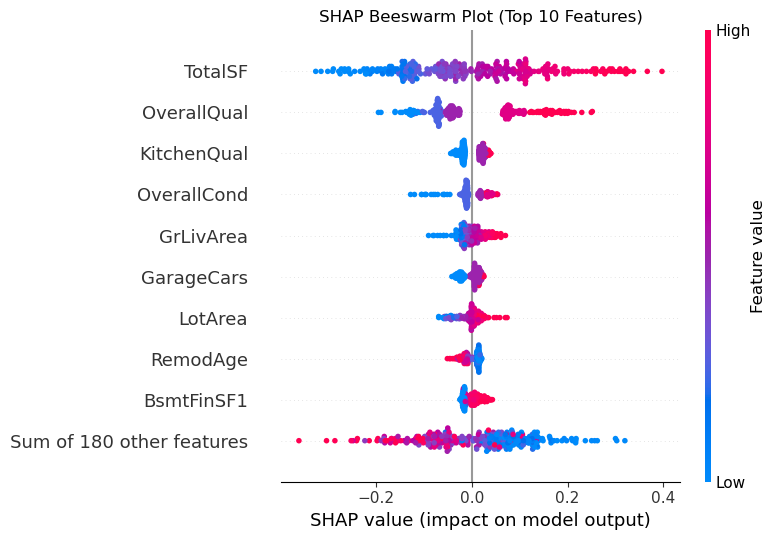

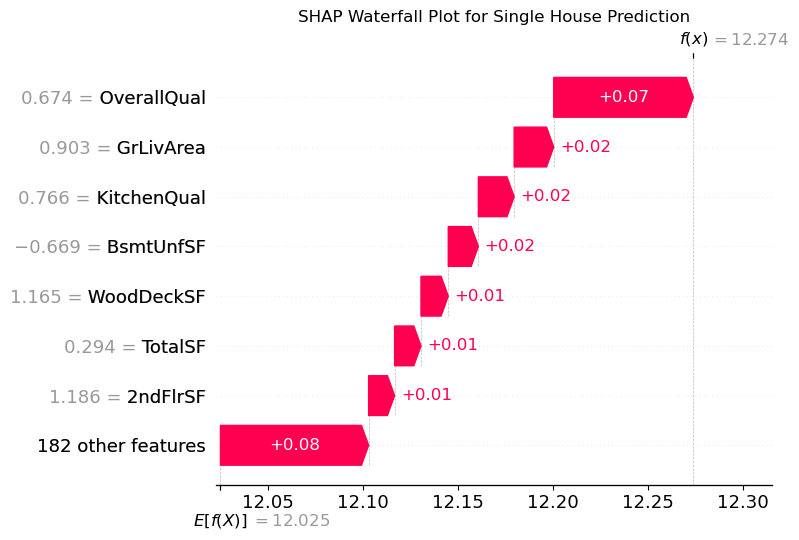

In [30]:
# Bonus: SHAP interpretation
import shap

explainer = shap.TreeExplainer(best_model)
shap_values = explainer(X_test)

# Beeswarm plot
plt.figure(figsize=(8, 5))
shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.title("SHAP Beeswarm Plot (Top 10 Features)")
plt.tight_layout()
plt.show()

# Waterfall plot for 1 sample
plt.figure(figsize=(8, 5))
shap.plots.waterfall(shap_values[0], max_display=8, show=False)
plt.title("SHAP Waterfall Plot for Single House Prediction")
plt.tight_layout()
plt.show()

## Step 8: Pipeline, Deployment & GitHub Submission

### 8.1 Save the Final Pipeline
- Wrap best model into pipeline and save with joblib.
- Save: joblib.dump(best_model, 'house_price_model.pkl').
- Test it: load the pickle and predict the sale price for 5 sample rows. Print predicted vs actual prices.

In [31]:
# Save model
joblib.dump(best_model, 'house_price_model.pkl')
print("Model saved to house_price_model.pkl successfully!")

# Load and test on 5 sample rows
loaded_model = joblib.load('house_price_model.pkl')
sample_X = X_test.iloc[:5]
sample_y_actual = y_test_orig.iloc[:5].values
sample_y_pred = np.expm1(loaded_model.predict(sample_X))

test_results_df = pd.DataFrame({
    'Actual Price ($)': [f"${a:,.2f}" for a in sample_y_actual],
    'Predicted Price ($)': [f"${p:,.2f}" for p in sample_y_pred],
    'Difference ($)': [f"${abs(p - a):,.2f}" for p, a in zip(sample_y_pred, sample_y_actual)],
    'Error %': [f"{abs(p - a)/a*100:.2f}%" for p, a in zip(sample_y_pred, sample_y_actual)]
})

print("\nPredictions on 5 Test Samples:")
test_results_df

Model saved to house_price_model.pkl successfully!

Predictions on 5 Test Samples:


,Actual Price ($),Predicted Price ($),Difference ($),Error %
0,"$190,000.00","$214,002.66","$24,002.66",12.63%
1,"$100,000.00","$93,532.37","$6,467.63",6.47%
2,"$115,000.00","$112,960.55","$2,039.45",1.77%
3,"$159,000.00","$153,355.45","$5,644.55",3.55%
4,"$315,500.00","$332,952.88","$17,452.87",5.53%
